# Deep Q: chess bots that learn from their own games

The *Convolutional* bots learned by studying 10,000 master games. The *Deep Q* bots
never see a master game's result: they learn the value of a position from games they
play, by **Q-learning**. This notebook explains the method, trains the bots (locally
for a demonstration, or on Modal GPUs for real), compares two ways of training them,
and puts a bot that beats Greedy into the web app.

| Step | What happens |
|---|---|
| 1. Setup | Load the training module and pick a device |
| 2. What the network sees | The 19 standard planes plus 4 **heuristic planes**: attacks and pieces in danger |
| 3. Q-learning | The target a move is trained towards, worked through on real positions |
| 4. Two training loops | Self-play, and play against the medium Convolutional bot searching 2 plies |
| 5. Training | Locally here (a short demonstration), or on Modal within a dollar budget |
| 6. Results | Score against Jester and Greedy over training time, loss, how games end |
| 7. Comparison | Which loop learned more for the same money |
| 8. Deployment | Export the best network to the web app, once it beats Greedy |

**Where the code lives.** The machinery is in
[`ai/dqn_training.py`](dqn_training.py) (networks, games, replay buffer, targets,
training, export) and [`ai/dqn_modal.py`](dqn_modal.py) (GPU training on Modal). The
design and its trade-offs are in [`ai/DEEP_Q_PLAN.md`](DEEP_Q_PLAN.md).

## 1. Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, str(Path.cwd()))          # run from ai/
import chess_engine as ce
import dqn_training as dq

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUNS = Path("runs")                          # Modal runs downloaded here, and local runs
PROFILE = "gpu" if DEVICE.type == "cuda" else "cpu"
LOCAL_MINUTES = 3.0                          # per loop, when training here
print(f"device: {DEVICE}, profile: {PROFILE}, CUDA kernels: {ce.cuda_available()}")

device: cpu, profile: cpu, CUDA kernels: False


## 2. What the network sees

Every position is encoded from the side to move's point of view, like the Convolutional
models' input: 12 piece planes, castling rights, en passant, the 50-move clock. The Deep Q
networks get four more planes, computed by the C++ engine (`core/encode.hpp`, the same
code in Python, CUDA and the browser):

| plane | meaning |
|---|---|
| 19 | how many of our pieces attack each square (÷ 4) |
| 20 | how many of theirs do |
| 21 | our pieces **in danger**: attacked, and undefended or attacked by a cheaper piece |
| 22 | their pieces in danger |

A small linear **prior** reads 21 hand-made features from these planes (material, material
and pieces in danger, in check, pieces on and attacks into d4/e4/d5/e5) and adds them to
the network's output. Its weights start **random** and are learned with the rest.

r . b q k b . r 
p p p p . p p p 
. . n . . n . . 
. . . . p . . Q 
. . B . P . . . 
. . . . . . . . 
P P P P . P P P 
R N B . K . N R 



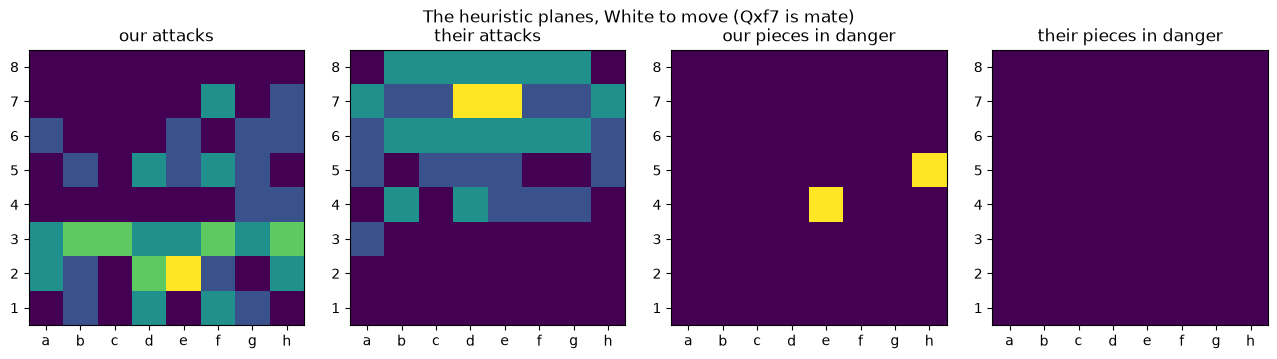

,our_pawns,our_knights,our_bishops,our_rooks,our_queens,our_king,their_pawns,their_knights,their_bishops,their_rooks,...,their_king,our_material_in_danger,their_material_in_danger,our_pieces_in_danger,their_pieces_in_danger,in_check,our_centre_pieces,their_centre_pieces,our_centre_attacks,their_centre_attacks
value,8.0,2.0,2.0,2.0,1.0,1.0,8.0,2.0,2.0,2.0,...,1.0,1.0,0.0,2.0,0.0,0.0,1.0,1.0,0.75,1.25


In [2]:
fen = "r1bqkb1r/pppp1ppp/2n2n2/4p2Q/2B1P3/8/PPPP1PPP/RNB1K1NR w KQkq - 4 4"
game = ce.Game(fen)
x = game.encode(ce.HEURISTIC_PLANES)
print(game)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, p in zip(axes, range(19, 23)):
    ax.imshow(x[p], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(ce.PLANE_NAMES[p].replace("_", " "))
    ax.set_xticks(range(8), list("abcdefgh"))
    ax.set_yticks(range(8), [str(8 - r) for r in range(8)])
fig.suptitle("The heuristic planes, White to move (Qxf7 is mate)")
plt.tight_layout()
plt.show()
features = dq.heuristic_features(torch.from_numpy(x[None]))[0]
pd.Series(features.numpy(), index=dq.FEATURE_NAMES).to_frame("value").T

## 3. Q-learning

**Q(s, a)** is the expected final score (1 win, ½ draw, 0 loss) for the player who
plays move *a* in position *s*, if both sides then play well. Chess moves are
deterministic, so Q(s, a) is the value of the position the move leads to, its
**afterstate**: Q(s, a) = 1 − V(s·a), where V is the value for the side to move there.

The network is trained towards a **target** built from what happened next, plus its
own estimate where the game was not over (bootstrapping):

* follow the game for *n* = 3 of the learner's moves, to a position *d*;
* if the game ended on the way, the target is the result;
* otherwise the side to move at *d* plays its best move, chosen by the online network
  and valued by a slowly moving copy, the **target network** (Double DQN);
* the value is flipped to the mover's point of view and discounted by γ = 0.995 per ply
  towards a draw, so faster wins are worth more.

The rules come first: a mate is a win and a rule draw (stalemate, 50 moves,
insufficient material, a third repetition) is a draw, whatever the network thinks.

**A second formulation**, the textbook *action-head* DQN, outputs a Q-value for each of
4,672 possible moves (AlphaZero's 8×8×73 move encoding) from one forward pass. It is
trained by the same code for comparison; only the afterstate network plays in the web app.

In [3]:
net = dq.build_qnet(dq.config_for(PROFILE))          # untrained: the rules decide these
d = torch.from_numpy(ce.boards_from_fens([fen, "r1bqkb1r/pppp1Qpp/2n2n2/4p3/2B1P3/8/PPPP1PPP/RNB1K1NR b KQkq - 0 4"]))
dist = dq.bootstrap_dist(d, torch.tensor([0, 1], dtype=torch.uint8), net, net)
pd.DataFrame(dist.numpy(), columns=["win", "draw", "loss"],
             index=["White to move, mate in one", "Black is mated"]).round(3)

,win,draw,loss
"White to move, mate in one",1.0,0.0,0.0
Black is mated,0.0,0.0,1.0


## 4. Two training loops

The same network, with the same settings, is trained two ways:

| loop | the learner plays… | what it learns from |
|---|---|---|
| **self** | itself (both sides) | every move of every game |
| **cnn** | the medium Convolutional bot searching 2 plies | its own moves only; the opponent is part of the environment |

Half the games start from the initial position after a few random moves, half from a
position taken from the first 30 plies of a master game (positions only, never the
results), for variety. The learner explores by sampling moves in proportion to
exp(score / temperature), with the temperature lowered over the run, plus a 2% chance
of a random move.

Against a fixed, strong opponent the learner gets a consistent, meaningful signal from
the first game, but the opponent's 2-ply search makes each move about 1,000 times
more expensive than the learner's, so it plays far fewer games for the same money.
Self-play is cheap and the opponent improves with the learner, but early games are
weak on both sides.

## 5. Training

**On Modal (the real runs).** From the repository root, with a payment method on the
Modal account:

```sh
modal run --detach ai/dqn_modal.py --budget-usd 1.50     # both loops, $0.75 each, on L4 GPUs
modal volume get pychess-dqn small-afterstate-self ai/runs/
modal volume get pychess-dqn small-afterstate-cnn ai/runs/
```

**Here.** If no Modal runs are in `ai/runs/`, the next cell trains both loops for
`LOCAL_MINUTES` each on this machine: a demonstration that the code runs and learns, not a
strong bot. On a CPU the `cpu` profile plays 64 games at a time, and its opponent searches
1 ply instead of 2 to keep the demonstration short; the Modal runs use the `gpu` profile.

In [4]:
def find_run(loop):
    for name in (f"small-afterstate-{loop}", f"local-{PROFILE}-{loop}"):
        if (RUNS / name / "history.json").exists():
            return RUNS / name
    return None

runs = {}
for loop in ("self", "cnn"):
    run = find_run(loop)
    if run is None:
        run = RUNS / f"local-{PROFILE}-{loop}"
        cfg = dq.config_for(PROFILE, opponent=loop, max_minutes=LOCAL_MINUTES,
                            eval_every_minutes=LOCAL_MINUTES / 3)
        print(f"training {run.name} for {LOCAL_MINUTES} min")
        dq.train(cfg, run, DEVICE)
    runs[loop] = run
    print(f"{loop}: {run}")

training local-cpu-self for 3.0 min


[   1.0 min]       9,216 positions       51 games      16 steps | loss 3.0766 | vs Jester 54% | vs Greedy 0% (Elo -1200) | 149 pos/s | ends: {'mate': 1.0}


[   2.2 min]      12,288 positions       74 games      40 steps | loss 0.8951 | vs Jester 57% | vs Greedy 3% (Elo -636) | 51 pos/s | ends: {'mate': 0.913, 'stalemate': 0.043, 'repetition': 0.043}


[   3.0 min]      14,080 positions       88 games      54 steps | loss 0.6113 | vs Jester 66% | vs Greedy 5% (Elo -512) | 55 pos/s | ends: {'mate': 0.929, 'stalemate': 0.071}
done: best vs Greedy 5% at 3.02 min (does not beat Greedy yet)
self: runs/local-cpu-self
training local-cpu-cnn for 3.0 min


[   1.0 min]       3,609 positions      152 games       6 steps | loss 0.8664 | vs Jester 56% | vs Greedy 5% (Elo -512) | 60 pos/s | ends: {'mate': 0.993, 'repetition': 0.007}


[   2.2 min]       6,243 positions      264 games      27 steps | loss 0.7955 | vs Jester 60% | vs Greedy 1% (Elo -759) | 43 pos/s | ends: {'mate': 0.982, 'repetition': 0.018}


[   3.0 min]       7,889 positions      342 games      40 steps | loss 0.7556 | vs Jester 55% | vs Greedy 8% (Elo -436) | 48 pos/s | ends: {'mate': 0.949, 'repetition': 0.051}
done: best vs Greedy 8% at 3.02 min (does not beat Greedy yet)
cnn: runs/local-cpu-cnn


## 6. Results

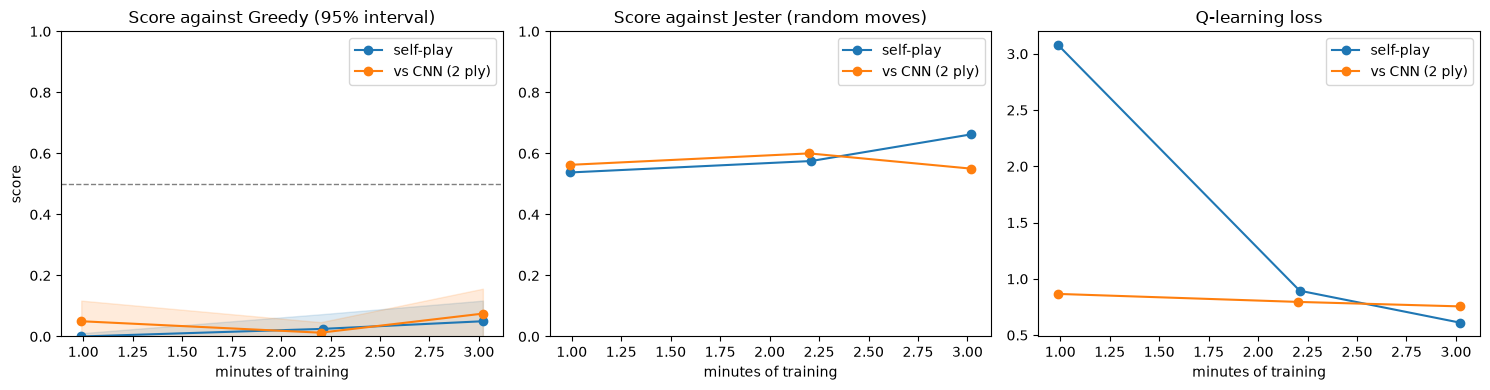

In [5]:
def history(run):
    rows = []
    for h in json.loads((run / "history.json").read_text()):
        row = {k: h[k] for k in ("minutes", "positions", "games", "train_steps", "loss", "predicted_score",
                                 "positions_per_s", "mean_game_plies", "beats_greedy")}
        for opp, r in h["results"].items():
            row[f"score vs {opp}"] = r["score"]
            row[f"Elo vs {opp}"] = r["elo"]
            row[f"Elo low vs {opp}"] = r["elo_low"]
            row[f"Elo high vs {opp}"] = r["elo_high"]
        row["endings"] = h["endings"]
        rows.append(row)
    return pd.DataFrame(rows)

hist = {loop: history(run) for loop, run in runs.items()}
colours = {"self": "tab:blue", "cnn": "tab:orange"}
labels = {"self": "self-play", "cnn": "vs CNN (2 ply)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for loop, h in hist.items():
    axes[0].plot(h["minutes"], h["score vs greedy"], "o-", color=colours[loop], label=labels[loop])
    axes[0].fill_between(h["minutes"], 1 / (1 + 10 ** (-h["Elo low vs greedy"] / 400)),
                         1 / (1 + 10 ** (-h["Elo high vs greedy"] / 400)), color=colours[loop], alpha=0.15)
    axes[1].plot(h["minutes"], h["score vs jester"], "o-", color=colours[loop], label=labels[loop])
    axes[2].plot(h["minutes"], h["loss"], "o-", color=colours[loop], label=labels[loop])
axes[0].axhline(0.5, color="grey", ls="--", lw=1)
axes[0].set(title="Score against Greedy (95% interval)", xlabel="minutes of training", ylabel="score", ylim=(0, 1))
axes[1].set(title="Score against Jester (random moves)", xlabel="minutes of training", ylim=(0, 1))
axes[2].set(title="Q-learning loss", xlabel="minutes of training")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

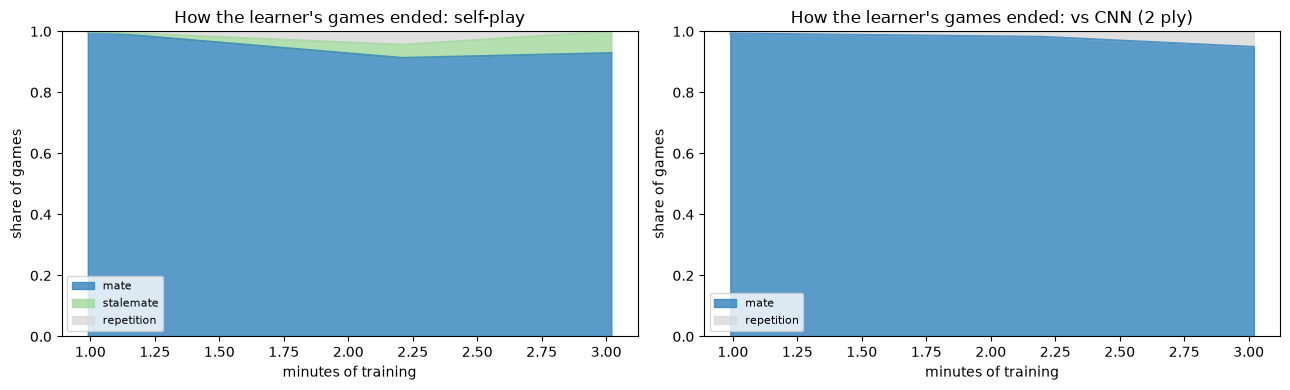

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (loop, h) in zip(axes, hist.items()):
    endings = pd.DataFrame(list(h["endings"])).fillna(0)
    endings.index = h["minutes"]
    endings.plot.area(ax=ax, stacked=True, alpha=0.8, cmap="tab20c")
    ax.set(title=f"How the learner's games ended: {labels[loop]}", xlabel="minutes of training",
           ylabel="share of games", ylim=(0, 1))
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## 7. Comparison

For the same budget, which loop produced the stronger bot? The table shows each run's
throughput and its best evaluation.

In [7]:
rows = {}
for loop, h in hist.items():
    best = h.loc[h["score vs greedy"].idxmax()]
    rows[labels[loop]] = {
        "minutes": h["minutes"].iloc[-1], "positions played": int(h["positions"].iloc[-1]),
        "games": int(h["games"].iloc[-1]), "training steps": int(h["train_steps"].iloc[-1]),
        "positions / s": round(h["positions_per_s"].mean()),
        "best score vs Greedy": round(best["score vs greedy"], 3),
        "Elo vs Greedy (95% CI)": f"{best['Elo vs greedy']:+.0f} ({best['Elo low vs greedy']:+.0f} … "
                                  f"{best['Elo high vs greedy']:+.0f})",
        "at minute": best["minutes"], "beats Greedy": bool(h["beats_greedy"].any()),
    }
comparison = pd.DataFrame(rows).T
comparison

,minutes,positions played,games,training steps,positions / s,best score vs Greedy,Elo vs Greedy (95% CI),at minute,beats Greedy
self-play,3.02,14080,88,54,85,0.05,-512 (-1200 … -350),3.02,False
vs CNN (2 ply),3.02,7889,342,40,50,0.075,-436 (-1200 … -292),3.02,False


## 8. Deployment

A network goes into the web app once it **beats Greedy**: a score above 50% with the
Elo interval above zero. `dq.deploy` refuses otherwise. It exports the best weights to
`web/public/models/deep_q_<size>.onnx` and lists them in `manifest.json` as a
`deep-q` model with the 23-plane encoding; the web app then offers Deep Q at that size
(other sizes say "Still training…").

In [8]:
winners = {loop: h["score vs greedy"].max() for loop, h in hist.items() if h["beats_greedy"].any()}
if winners:
    loop = max(winners, key=winners.get)
    print(f"deploying the {labels[loop]} network ({winners[loop]:.0%} against Greedy)")
    entry = dq.deploy(runs[loop])
    print(json.dumps(entry, indent=2))
else:
    print("No run beats Greedy yet: nothing deployed. Train longer (a larger --budget-usd) and run this again.")

No run beats Greedy yet: nothing deployed. Train longer (a larger --budget-usd) and run this again.
